## Loading the dataset

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

In [2]:
# Shared appearance for new pandas and Matplotlib plots.
# Keep axis scales, bins, and whisker rules specific to each analysis.
plt.rcParams.update({
    "figure.figsize": (9, 4.5),
    "figure.dpi": 120,
    "figure.autolayout": True,
    "figure.facecolor": "white",
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "font.family": "sans-serif",
    "font.size": 10,
    "text.color": "#183153",
    "axes.facecolor": "white",
    "axes.edgecolor": "#94a3b8",
    "axes.labelcolor": "#183153",
    "axes.labelsize": 11,
    "axes.labelpad": 8,
    "axes.titlesize": 13,
    "axes.titlepad": 12,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.axisbelow": True,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": "#94a3b8",
    "grid.alpha": 0.18,
    "grid.linewidth": 0.8,
    "axes.prop_cycle": plt.cycler(color=[
        "#6baed6", "#3182bd", "#183153",
        "#e6550d", "#31a354", "#756bb1",
    ]),
    "xtick.color": "#475569",
    "ytick.color": "#475569",
    "lines.linewidth": 2,
    "patch.edgecolor": "white",
    "patch.force_edgecolor": True,
    "patch.linewidth": 0.8,
    "legend.frameon": False,
    "boxplot.patchartist": True,
    "boxplot.showmeans": True,
    "boxplot.boxprops.color": "#3182bd",
    "boxplot.whiskerprops.color": "#3182bd",
    "boxplot.capprops.color": "#3182bd",
    "boxplot.medianprops.color": "#183153",
    "boxplot.medianprops.linewidth": 2,
    "boxplot.flierprops.marker": "o",
    "boxplot.flierprops.markersize": 3,
    "boxplot.flierprops.markerfacecolor": "#3182bd40",
    "boxplot.flierprops.markeredgecolor": "none",
    "boxplot.meanprops.marker": "D",
    "boxplot.meanprops.markersize": 5,
    "boxplot.meanprops.markerfacecolor": "#e6550d",
    "boxplot.meanprops.markeredgecolor": "white",
})

In [3]:
from recsys.data import load_movielens

In [4]:
dataset = load_movielens("../data/ml-1m")

## Inspect the dataset

### Users

In [5]:
users = dataset.users
users.head()

,user_id,gender,age,occupation,zip_code
0,1,F,1,10,48067
1,2,M,56,16,70072
2,3,M,25,15,55117
3,4,M,45,7,02460
4,5,M,25,20,55455


In [6]:
users.info()

<class 'pandas.DataFrame'>
RangeIndex: 6040 entries, 0 to 6039
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     6040 non-null   int64 
 1   gender      6040 non-null   string
 2   age         6040 non-null   int64 
 3   occupation  6040 non-null   int64 
 4   zip_code    6040 non-null   string
dtypes: int64(3), string(2)
memory usage: 236.1 KB


In [7]:
users["user_id"].nunique()

6040

There are 6040 users as described in the project docs. All entries are non-null and all user_ids are unique.

We can inspect the age, gender and occupation distributions

In [8]:
age_labels = {
    1: "Under 18",
    18: "18–24",
    25: "25–34",
    35: "35–44",
    45: "45–49",
    50: "50–55",
    56: "56+",
}

occupation_labels = {
    0: "Other / unspecified",
    1: "Academic / educator",
    2: "Artist",
    3: "Clerical / admin",
    4: "College / grad student",
    5: "Customer service",
    6: "Doctor / health care",
    7: "Executive / managerial",
    8: "Farmer",
    9: "Homemaker",
    10: "K–12 student",
    11: "Lawyer",
    12: "Programmer",
    13: "Retired",
    14: "Sales / marketing",
    15: "Scientist",
    16: "Self-employed",
    17: "Technician / engineer",
    18: "Tradesman / craftsman",
    19: "Unemployed",
    20: "Writer",
}

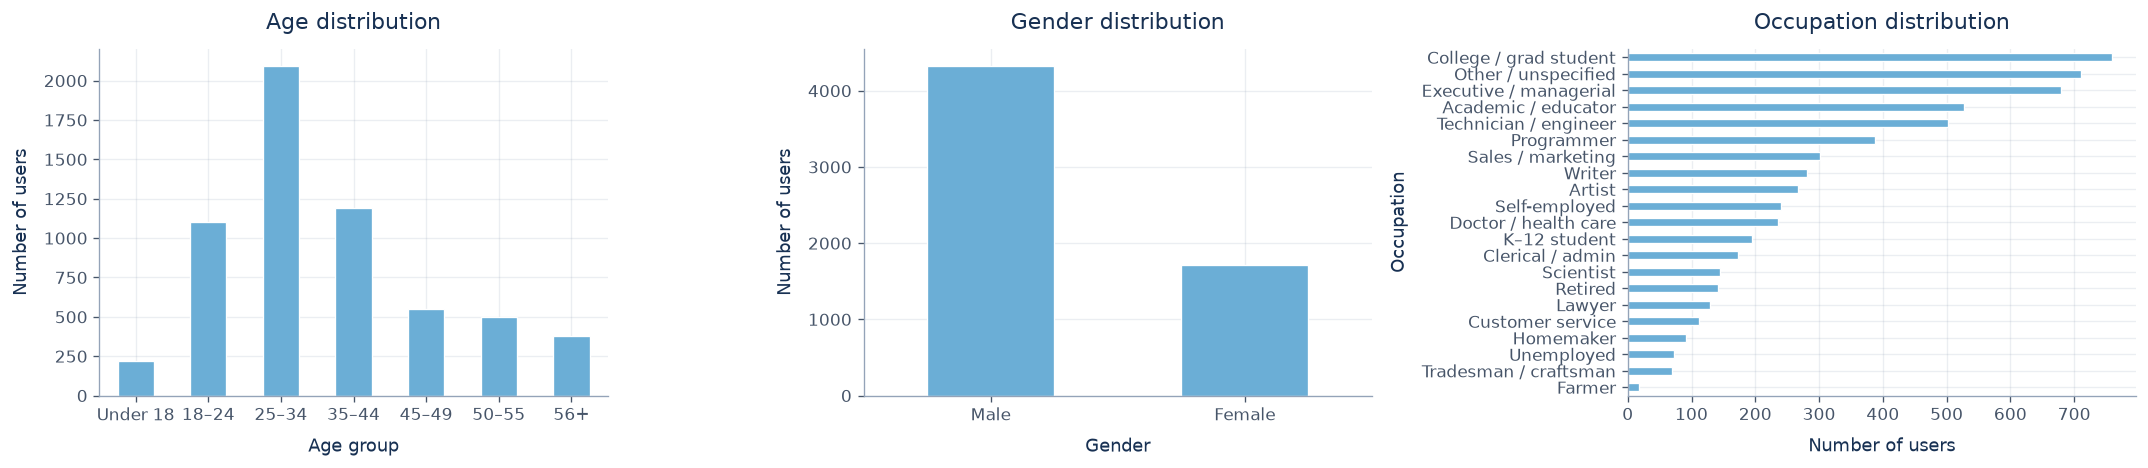

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))

dataset.users["age"].value_counts().sort_index().rename(
    index=age_labels
).plot.bar(
    ax=axes[0], title="Age distribution",
    xlabel="Age group", ylabel="Number of users", rot=0,
)

dataset.users["gender"].value_counts().rename(
    index={"F": "Female", "M": "Male"}
).plot.bar(
    ax=axes[1], title="Gender distribution",
    xlabel="Gender", ylabel="Number of users", rot=0,
)

dataset.users["occupation"].value_counts().rename(
    index=occupation_labels
).sort_values().plot.barh(
    ax=axes[2], title="Occupation distribution",
    xlabel="Number of users", ylabel="Occupation",
)

plt.tight_layout()
plt.show()

### Movies

In [10]:
movies = dataset.movies
movies.head()

,item_id,title,genres
0,1,Toy Story (1995),Animation|Children's|Comedy
1,2,Jumanji (1995),Adventure|Children's|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama
4,5,Father of the Bride Part II (1995),Comedy


In [11]:
movies.info()

<class 'pandas.DataFrame'>
RangeIndex: 3883 entries, 0 to 3882
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   item_id  3883 non-null   int64 
 1   title    3883 non-null   string
 2   genres   3883 non-null   string
dtypes: int64(1), string(2)
memory usage: 91.1 KB


In [12]:
movies["item_id"].nunique()

3883

There are 3883 unique movies.

Let's explore the release year and genre distribution 

In [13]:
release_years = (
    dataset.movies["title"]
    .str.extract(r"\((\d{4})\)$", expand=False)
    .astype("Int64")
)

genres = dataset.movies["genres"].str.split("|", regex=False).explode()

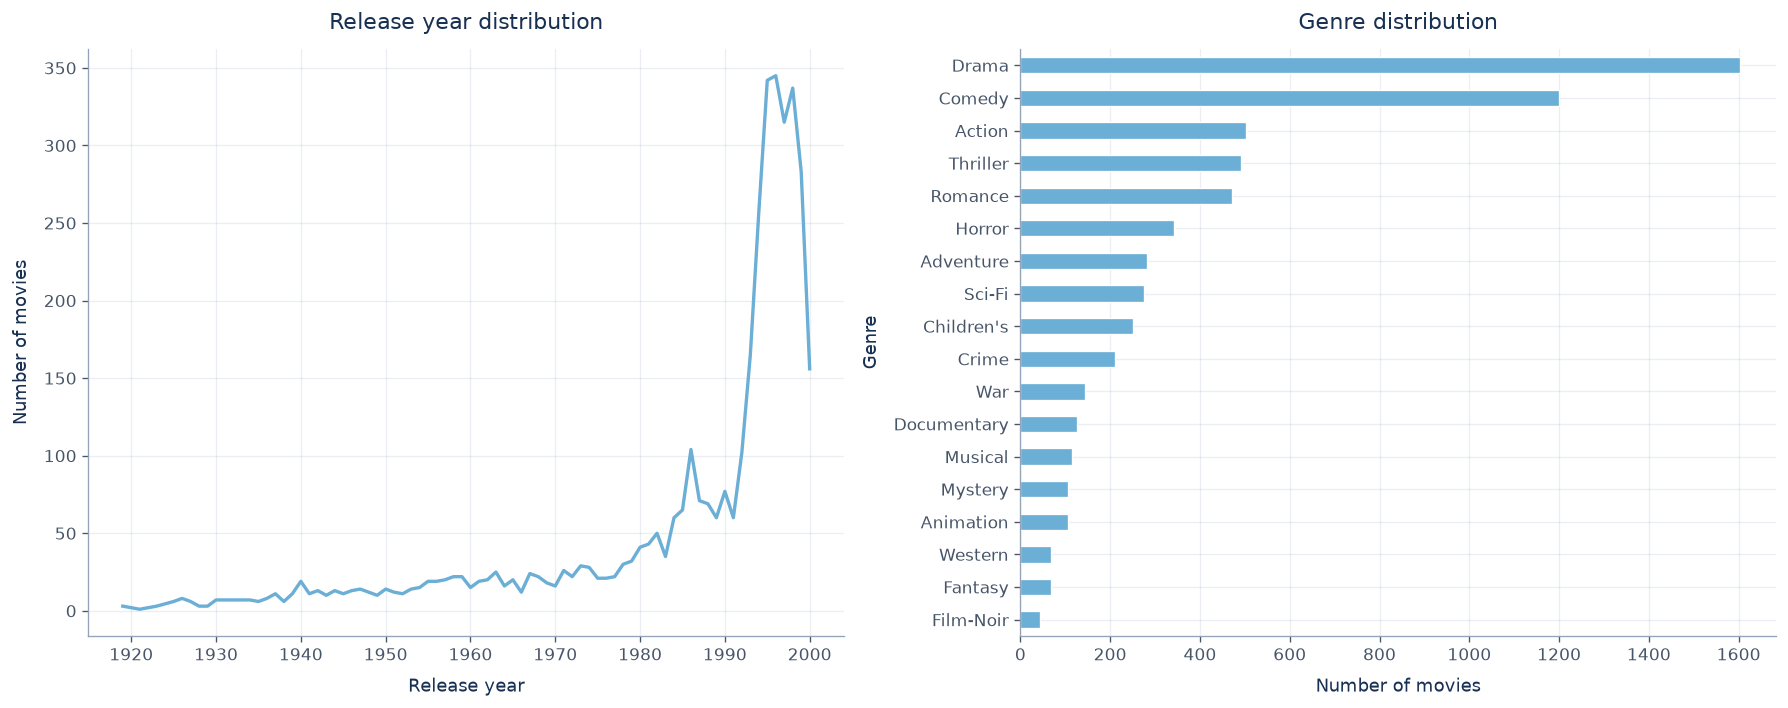

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

release_years.value_counts().sort_index().plot(
    ax=axes[0], title="Release year distribution",
    xlabel="Release year", ylabel="Number of movies",
)

genres.value_counts().sort_values().plot.barh(
    ax=axes[1], title="Genre distribution",
    xlabel="Number of movies", ylabel="Genre",
)

plt.tight_layout()
plt.show()

### Ratings

In [15]:
ratings = dataset.ratings
ratings.head()

,user_id,item_id,rating,timestamp
0,1,1193,5,978300760
1,1,661,3,978302109
2,1,914,3,978301968
3,1,3408,4,978300275
4,1,2355,5,978824291


In [16]:
ratings.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000209 entries, 0 to 1000208
Data columns (total 4 columns):
 #   Column     Non-Null Count    Dtype
---  ------     --------------    -----
 0   user_id    1000209 non-null  int64
 1   item_id    1000209 non-null  int64
 2   rating     1000209 non-null  int64
 3   timestamp  1000209 non-null  int64
dtypes: int64(4)
memory usage: 30.5 MB


In [27]:
timestamps = pd.to_datetime(
    dataset.ratings["timestamp"], unit="s", utc=True
)

month_bins = pd.date_range(
    start=timestamps.min().normalize().replace(day=1),
    end=timestamps.max().normalize().replace(day=1) + pd.offsets.MonthBegin(1),
    freq="MS",
)

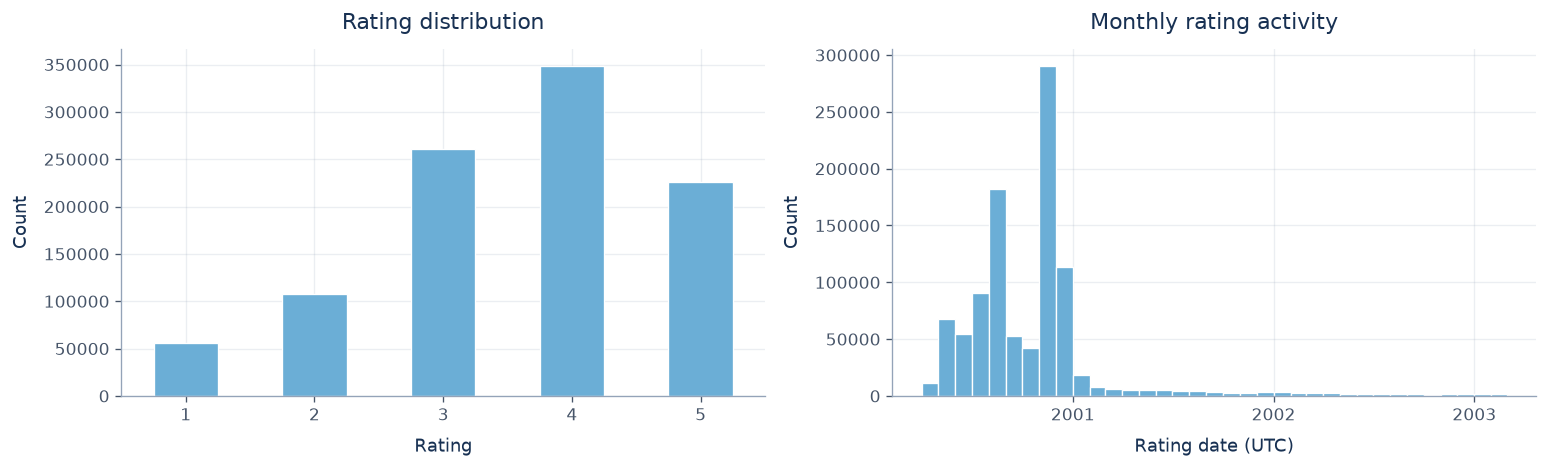

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

dataset.ratings["rating"].value_counts().sort_index().plot.bar(
    ax=axes[0], title="Rating distribution",
    xlabel="Rating", ylabel="Count", rot=0,
)

timestamps.hist(
    ax=axes[1],
    bins=mdates.date2num(month_bins.to_pydatetime()),
)
axes[1].set(
    title="Monthly rating activity",
    xlabel="Rating date (UTC)", ylabel="Count",
)

locator = mdates.AutoDateLocator(minticks=3, maxticks=6)
axes[1].xaxis.set_major_locator(locator)
axes[1].xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))

plt.tight_layout()
plt.show()

In terms of rating distribution, low ratings seem under represented. In the temporal distribution of the rating counts we see most of the ratings happened in the year 2000, there is a great drop for ratings in 2001 and the rating counts continue to decrease slowly with time.

### Density

The density is the ratio of the number of ratings available to the total number of possible ratings there can be.

In [19]:
density = len(ratings) / (
    ratings["user_id"].nunique() * ratings["item_id"].nunique()
)
print(f"Density: {density:.2%}")

Density: 4.47%


To get a feel of this density we can take a random sample of users and movies and plot the ratings matrix

In [20]:
sampled_users = dataset.users["user_id"].sample(n=100, random_state=42)
sampled_movies = dataset.movies["item_id"].sample(n=200, random_state=42)

sample = ratings[
    ratings["user_id"].isin(sampled_users)
    & ratings["item_id"].isin(sampled_movies)
]

# Reindex to retain sampled users/movies with no ratings in this sample.
observed = (
    pd.crosstab(sample["user_id"], sample["item_id"])
    .reindex(index=sampled_users, columns=sampled_movies, fill_value=0)
    .gt(0)
)

sample_density = observed.to_numpy().mean()

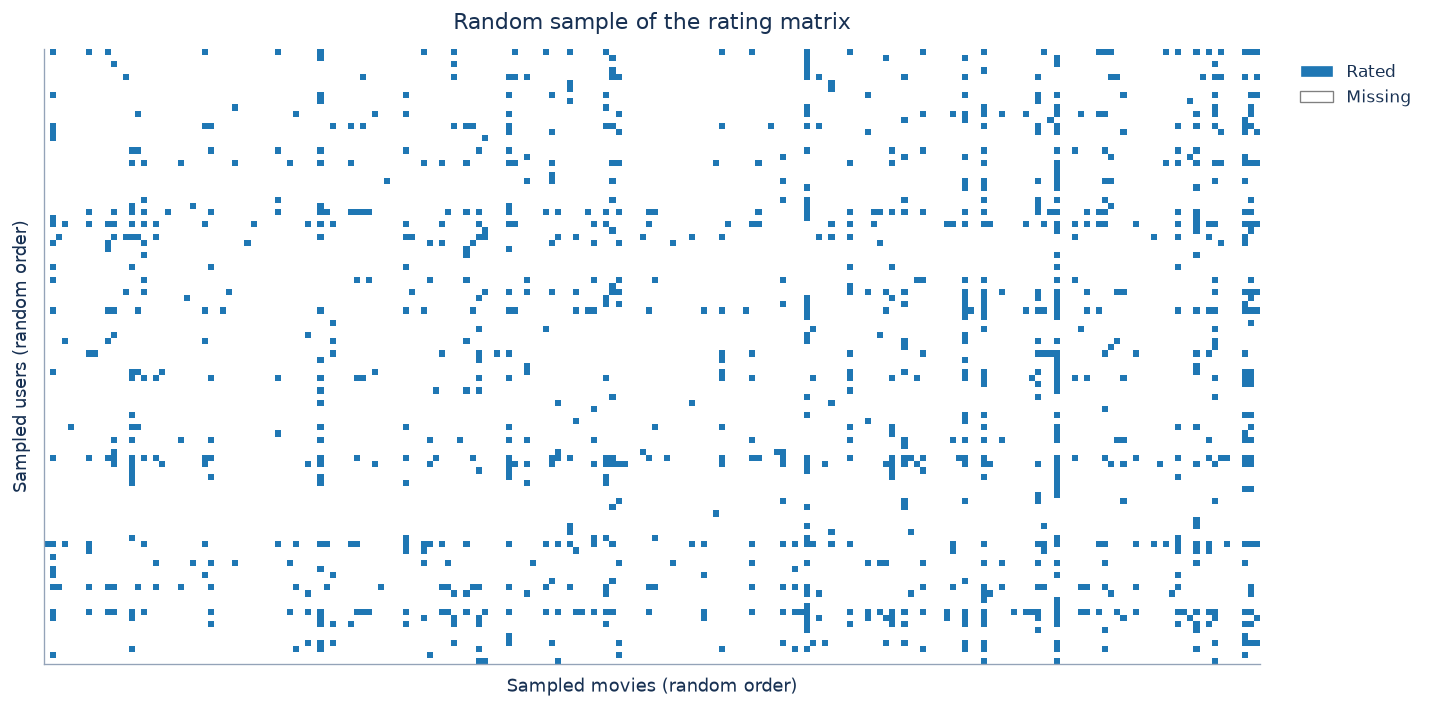

In [21]:
fig, ax = plt.subplots(figsize=(12, 6))

ax.imshow(
    observed,
    cmap=ListedColormap(["white", "tab:blue"]),
    interpolation="nearest",
    aspect="auto",
    vmin=0, vmax=1,
)

ax.set(
    title="Random sample of the rating matrix",
    xlabel="Sampled movies (random order)",
    ylabel="Sampled users (random order)",
    xticks=[], yticks=[],
)

ax.legend(
    handles=[
        Patch(facecolor="tab:blue", label="Rated"),
        Patch(facecolor="white", edgecolor="gray", label="Missing"),
    ],
    loc="upper left", bbox_to_anchor=(1.02, 1),
)

plt.tight_layout()
plt.show()

### Distribution of interactions per user

In [22]:
interactions_per_user = ratings.groupby("user_id").size()

user_counts = interactions_per_user.value_counts().sort_index()
cumulative_share = user_counts.cumsum() / user_counts.sum()
quartiles = interactions_per_user.quantile([0.25, 0.50, 0.75])
ecdf = pd.concat([pd.Series([0.0], index=[0]), cumulative_share])

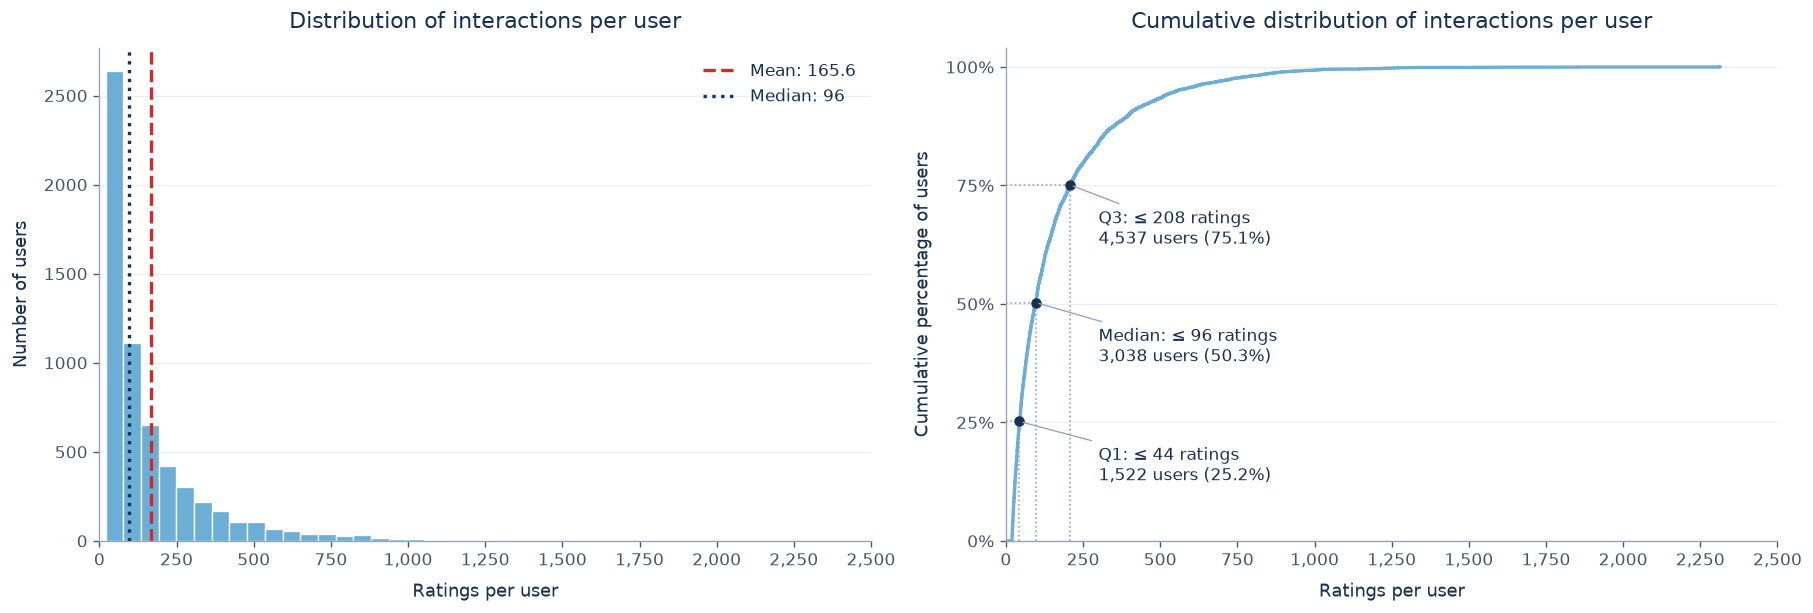

In [23]:
fig, axes = plt.subplots(
    1, 2, figsize=(15, 5), sharex=True, layout="constrained"
)

interactions_per_user.plot.hist(
    ax=axes[0], bins=40,
    title="Distribution of interactions per user",
    xlabel="Ratings per user", ylabel="Number of users",
)
axes[0].axvline(
    interactions_per_user.mean(), color="tab:red", linestyle="--",
    label=f"Mean: {interactions_per_user.mean():.1f}",
)
axes[0].axvline(
    interactions_per_user.median(), color="#183153", linestyle=":",
    label=f"Median: {interactions_per_user.median():g}",
)
axes[0].legend()

ecdf.plot(
    ax=axes[1], drawstyle="steps-post", linewidth=2,
    title="Cumulative distribution of interactions per user",
    xlabel="Ratings per user", ylabel="Cumulative percentage of users",
)
axes[1].set_ylim(0, 1.04)
axes[1].set_yticks(
    [0, 0.25, 0.50, 0.75, 1],
    labels=["0%", "25%", "50%", "75%", "100%"],
)

for name, cutoff in zip(["Q1", "Median", "Q3"], quartiles):
    n_users = interactions_per_user.le(cutoff).sum()
    share = n_users / len(interactions_per_user)
    axes[1].vlines(cutoff, 0, share, color="#94a3b8", linestyle=":", linewidth=1)
    axes[1].hlines(share, 0, cutoff, color="#94a3b8", linestyle=":", linewidth=1)
    axes[1].scatter([cutoff], [share], color="#183153", s=30, zorder=3)
    axes[1].annotate(
        f"{name}: ≤ {cutoff:g} ratings\n{n_users:,} users ({share:.1%})",
        xy=(cutoff, share), xytext=(300, share - 0.05),
        textcoords="data", va="top", fontsize=10,
        arrowprops=dict(arrowstyle="-", color="#94a3b8", linewidth=0.8),
    )

for ax in axes:
    ax.set_xscale("linear")
    ax.set_xlim(0, max(2500, interactions_per_user.max() * 1.05))
    ticks = range(0, 2501, 250)
    ax.set_xticks(ticks, labels=[f"{tick:,}" for tick in ticks])
    ax.grid(False)
    ax.grid(axis="y", alpha=0.18)

plt.show()


We see a very skewed distribution of ratings per user: most users rank a small portion of the total movies, with more than 75% of users rating less than 250 out of the 38883 movies, while some rank more than 1000.

### Distribution of interactions per item

In [24]:
interactions_per_item = (
    ratings.groupby("item_id").size()
    .reindex(movies["item_id"], fill_value=0)
)

item_counts = interactions_per_item.value_counts().sort_index()
cumulative_share = item_counts.cumsum() / item_counts.sum()
quartiles = interactions_per_item.quantile([0.25, 0.50, 0.75])
ecdf = pd.concat([pd.Series([0.0], index=[0]), cumulative_share])

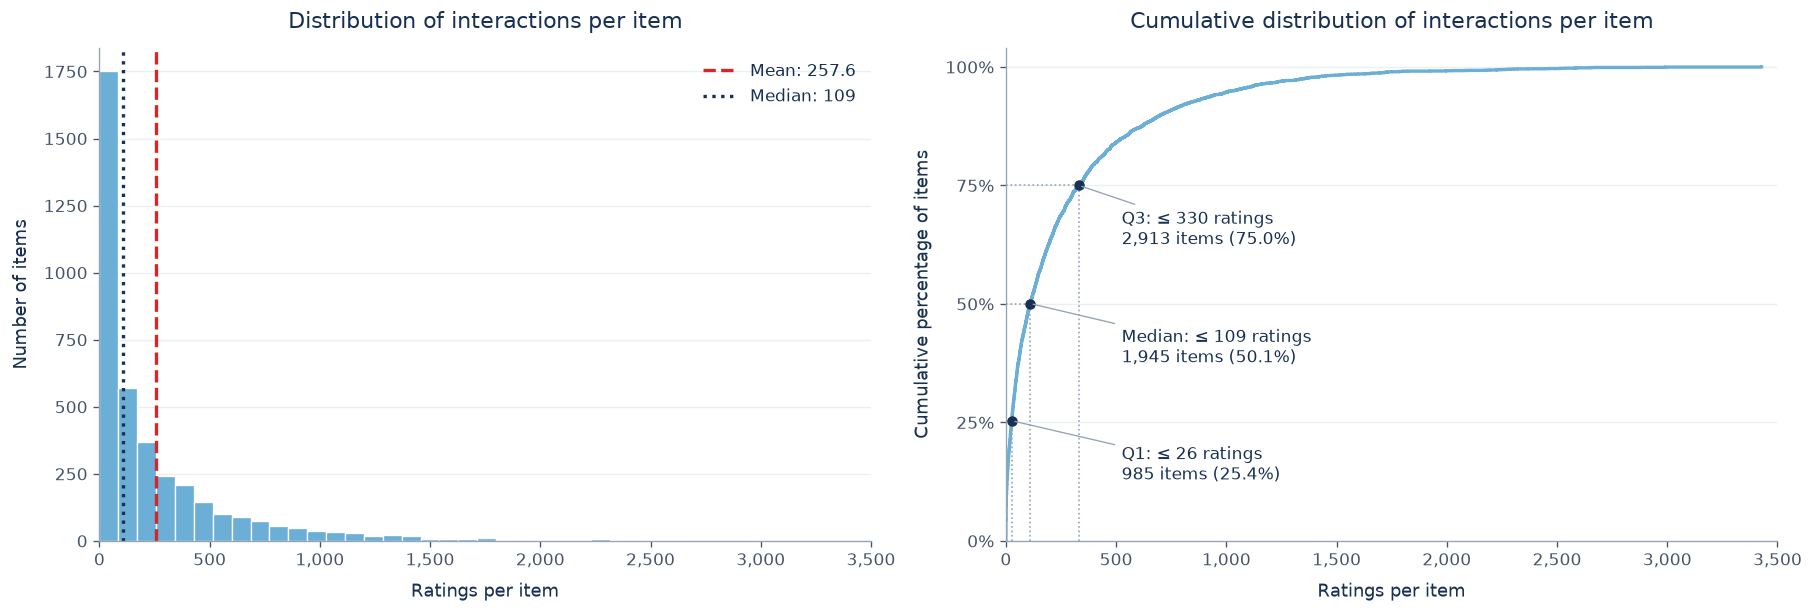

In [25]:
tick_step = 500
x_max = (
    (int(interactions_per_item.max()) + tick_step - 1) // tick_step
) * tick_step

fig, axes = plt.subplots(
    1, 2, figsize=(15, 5), sharex=True, layout="constrained"
)

interactions_per_item.plot.hist(
    ax=axes[0], bins=40,
    title="Distribution of interactions per item",
    xlabel="Ratings per item", ylabel="Number of items",
)
axes[0].axvline(
    interactions_per_item.mean(), color="tab:red", linestyle="--",
    label=f"Mean: {interactions_per_item.mean():.1f}",
)
axes[0].axvline(
    interactions_per_item.median(), color="#183153", linestyle=":",
    label=f"Median: {interactions_per_item.median():g}",
)
axes[0].legend()

ecdf.plot(
    ax=axes[1], drawstyle="steps-post", linewidth=2,
    title="Cumulative distribution of interactions per item",
    xlabel="Ratings per item", ylabel="Cumulative percentage of items",
)
axes[1].set_ylim(0, 1.04)
axes[1].set_yticks(
    [0, 0.25, 0.50, 0.75, 1],
    labels=["0%", "25%", "50%", "75%", "100%"],
)

for name, cutoff in zip(["Q1", "Median", "Q3"], quartiles):
    n_items = interactions_per_item.le(cutoff).sum()
    share = n_items / len(interactions_per_item)

    axes[1].vlines(
        cutoff, 0, share,
        color="#94a3b8", linestyle=":", linewidth=1,
    )
    axes[1].hlines(
        share, 0, cutoff,
        color="#94a3b8", linestyle=":", linewidth=1,
    )
    axes[1].scatter(
        [cutoff], [share], color="#183153", s=30, zorder=3,
    )
    axes[1].annotate(
        f"{name}: ≤ {cutoff:g} ratings\n{n_items:,} items ({share:.1%})",
        xy=(cutoff, share),
        xytext=(x_max * 0.15, share - 0.05),
        textcoords="data", va="top", fontsize=10,
        arrowprops=dict(
            arrowstyle="-", color="#94a3b8", linewidth=0.8,
        ),
    )

for ax in axes:
    ax.set_xscale("linear")
    ax.set_xlim(0, x_max)
    ticks = range(0, x_max + 1, tick_step)
    ax.set_xticks(ticks, labels=[f"{tick:,}" for tick in ticks])
    ax.grid(False)
    ax.grid(axis="y", alpha=0.18)

plt.show()

We see again a very skewed distribution: with the 75% of the items having less than 330 ratings, while a few items are ranked over 2000 times.